# A crash course in good and bad controls

This notebook translates the causal diagrams and linear-regression simulations in
[Carlos Cinelli’s R notebook](https://www.kaggle.com/code/carloscinelli/crash-course-in-good-and-bad-controls-linear-r),
 retrieved 2026-11-15, covering Models 1–18 and the variation of Model 11. It was very instructive to me to go through the computations in Python but all credit goes to Carlos Cinelli.


See also the accompanying paper by Carlos Cinelli, Andrew Forney, and Judea Pearl:
[A Crash Course in Good and Bad Controls](https://carloscinelli.com/files/Cinelli%20et%20al%20-%20A%20Crash%20Course%20in%20Good%20and%20Bad%20Controls.pdf).


## Estimation target

This is the total average causal effect of increasing X by one unit through an
intervention. The experiments hold every exogenous disturbance fixed, increase X by one, and propagate
that change through its descendants. In linear models used below, the resulting change in Y
is constant, so it also equals the average effect. It is 1 in every numerical example.

To understand the models presented below, the following concepts are important:

- A chain (X → Z → Y) transmits a causal effect of X on Y. 
- A fork (X ← Z → Y) can transmit confounding association. Conditioning on the middle variable Z blocks either route.
- A collider (X → Z ← Y) behaves differently: conditioning on it or a descendant can open an otherwise closed route. The causal structure, rather than correlation alone, determines which controls help.

Diagram legend: 

- filled circles are observed, 
- hollow circles are latent,
- red highlights the candidate control Z,
- A dashed arrow labelled “0 in simulation” preserves an arrow in the original graph whose coefficient is zero in the source’s example.


## Configuration

The notebook uses 5,000 observations per dataset and 1,000 replications in each of
Models 8, 9, 13, and 14.

Each model gets a stable integer seed, with separate streams for the displayed dataset and repeated experiment. Re-running a model cell
therefore reproduces its results independently of which other examples were run.


In [ ]:
from collections.abc import Callable, Sequence
from html import escape
from math import hypot, sqrt
from time import perf_counter

import numpy as np

Data = dict[str, np.ndarray]
Point = tuple[float, float]
Simulation = Callable[[np.random.Generator], Data]

N = 5_000
REPLICATIONS = 1_000
SEED = 20261115
results = {}
precision_results = {}
print(f"n={N:,}; replications={REPLICATIONS:,} per precision experiment")


def stream(name: str) -> np.random.Generator:
    """Use a stable name to reproduce a stream without Python's randomized hash()."""
    return np.random.default_rng([SEED, *name.encode("utf-8")])


n=5,000; replications=1,000 per precision experiment


## Ordinary least squares

Each column of the design matrix represents a predictor. The first column contains
ones for the intercept. NumPy’s `linalg.lstsq` fits all coefficients together by
minimizing the sum of squared residuals.

In [ ]:
def ols(y: Sequence[float], **predictors: Sequence[float]) -> dict[str, float]:
    """Fit a regression with an intercept and return the coefficients by name."""
    design = np.column_stack((np.ones(len(y)), *predictors.values()))
    coefficients, _, rank, _ = np.linalg.lstsq(design, y, rcond=None)
    if rank < design.shape[1]:
        raise ValueError("The regression coefficients are not uniquely determined")
    return dict(zip(("intercept", *predictors), coefficients.tolist()))


def compare(data: Data, baseline_controls: tuple[str, ...] = ()) -> dict:
    """Compare regressions before and after adding Z to the baseline controls."""
    fits = []
    for controls in (baseline_controls, (*baseline_controls, "z")):
        names = ("x", *controls)
        fit = ols(data["y"], **{name: data[name] for name in names})
        fits.append(fit)
        print("Y ~ 1 + " + " + ".join(name.upper() for name in names))
        print("  " + "   ".join(f"{name}={value: .6f}" for name, value in fit.items()))
    print("Total causal effect from the structural equations: 1\n")
    before = ",".join(name.upper() for name in baseline_controls) or "none"
    after = ",".join(name.upper() for name in (*baseline_controls, "z"))
    return {"first": fits[0], "adjusted": fits[1], "controls": f"{before} -> {after}"}


def asymptotic_sd_ratio(covariance: np.ndarray) -> float:
    """Derive the adjusted/unadjusted SD ratio from the covariance of (X, Y, Z)."""
    var_x, var_y, var_z = covariance.diagonal()
    cov_xy, cov_xz, cov_yz = covariance[0, 1], covariance[0, 2], covariance[1, 2]
    # Remove Z's linear contribution from X and Y.
    var_x_given_z = var_x - cov_xz**2 / var_z
    var_y_given_z = var_y - cov_yz**2 / var_z
    cov_xy_given_z = cov_xy - cov_xz * cov_yz / var_z
    # Outcome noise left after each regression, divided by usable X variation.
    residual_unadjusted = var_y - cov_xy**2 / var_x
    residual_adjusted = var_y_given_z - cov_xy_given_z**2 / var_x_given_z
    return sqrt((residual_adjusted / var_x_given_z) / (residual_unadjusted / var_x))


def precision(simulate: Simulation, rng: np.random.Generator) -> dict:
    """Measure sampling variability and derive an asymptotic comparison from data."""
    samples = np.empty((REPLICATIONS, 2))
    covariance_sum = np.zeros((3, 3))
    started = perf_counter()
    for row in samples:
        data = simulate(rng)
        row[0] = ols(data["y"], x=data["x"])["x"]
        row[1] = ols(data["y"], x=data["x"], z=data["z"])["x"]
        covariance_sum += np.cov([data["x"], data["y"], data["z"]])

    averages = samples.mean(axis=0)
    sds = samples.std(axis=0, ddof=1)
    derived_ratio = asymptotic_sd_ratio(covariance_sum / REPLICATIONS)
    print(f"{REPLICATIONS:,} paired replications; n={N:,}")
    print(f"{'Estimator':<14} {'Mean':>10} {'Bias':>10} {'Sampling SD':>13} {'MCSE(mean)':>12}")
    for label, average, sd in zip(("Unadjusted", "Adjusted"), averages, sds):
        bias = average - 1
        mcse = sd / sqrt(REPLICATIONS)
        print(f"{label:<14} {average:10.6f} {bias:10.6f} {sd:13.6f} {mcse:12.6f}")
    ratio = sds[1] / sds[0]
    print(f"Adjusted/unadjusted sampling SD: {ratio:.4f}")
    print(f"Asymptotic SD ratio estimated from data: {derived_ratio:.4f}")
    print(f"Elapsed: {perf_counter() - started:.1f} seconds")
    return {"means": averages, "sds": sds, "ratio": ratio, "derived_ratio": derived_ratio}


## SVG causal diagrams

The node positions and edge lists below come from the R source. The renderer uses
hand-set coordinates and curves arrows that would otherwise pass through a mediator.
An SVG object as the last expression in a cell is displayed by Jupyter and stored with
the notebook. The textual edge lists also describe each diagram without relying on color.


In [ ]:
class Diagram:
    def __init__(self, svg: str) -> None:
        self.svg = svg

    def _repr_svg_(self) -> str:
        return self.svg

    def __repr__(self) -> str:
        return "Causal diagram (SVG; see the textual edge list above)"


def move_toward(start: Point, end: Point, distance: float) -> Point:
    """Move a point along a line, leaving room for a node or arrowhead."""
    x, y = start
    end_x, end_y = end
    fraction = distance / hypot(end_x - x, end_y - y)
    return x + fraction * (end_x - x), y + fraction * (end_y - y)


def edge_path(start: Point, end: Point, curved: bool) -> tuple[str, Point]:
    """Return SVG path data and the position for an edge annotation."""
    ax, ay = start
    bx, by = end
    middle_x, middle_y = (ax + bx) / 2, (ay + by) / 2
    if curved:
        control = (middle_x, max(ay, by) + 105)
        sx, sy = move_toward(start=start, end=control, distance=25)
        ex, ey = move_toward(start=end, end=control, distance=27)
        cx, cy = control
        return f"M {sx} {sy} Q {cx} {cy} {ex} {ey}", (middle_x, middle_y + 76)

    sx, sy = move_toward(start=start, end=end, distance=25)
    ex, ey = move_toward(start=end, end=start, distance=27)
    return f"M {sx} {sy} L {ex} {ey}", (middle_x, middle_y - 12)


def draw_dag(
    title: str,
    edges: Sequence[tuple[str, str]],
    positions: dict[str, Point],
    *,
    latent: Sequence[str] = (),
    zero_edges: Sequence[tuple[str, str]] = (),
    curved: Sequence[tuple[str, str]] = (),
) -> Diagram:
    width = 760
    identifier = "dag-" + "-".join(title.lower().split())
    xs, ys = zip(*positions.values())
    left, top = min(xs), max(ys)
    x_span = max(xs) - left
    scale = min(150, 620 / x_span)
    offset = (width - scale*x_span) / 2
    points = {node: (offset + (x - left) * scale, 82 + (top - y) * 110)
              for node, (x, y) in positions.items()}
    bottom = max(y for x, y in points.values())
    height = bottom + (145 if curved else 110)
    legend_y = height - 42
    labels = {node: node.upper().replace("1", "₁").replace("2", "₂") for node in positions}
    description = "; ".join(f"{labels[a]} → {labels[b]}" for a, b in edges)
    # A separate SVG document is emitted for each diagram.
    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="760" height="{height}" '
             f'viewBox="0 0 760 {height}" role="img" aria-labelledby="{identifier}-title {identifier}-desc">',
             f'<title id="{identifier}-title">{escape(title)}</title>',
             f'<desc id="{identifier}-desc">{escape(description)}. Hollow nodes are latent.</desc>',
             '<rect width="100%" height="100%" fill="white" rx="12"/>',
             f'<defs><marker id="{identifier}-arrow" viewBox="0 0 10 10" refX="9" refY="5" '
             'markerWidth="7" markerHeight="7" orient="auto-start-reverse">'
             '<path d="M 0 0 L 10 5 L 0 10 z" fill="#475569"/></marker></defs>',
             f'<text x="380" y="29" text-anchor="middle" font-family="sans-serif" '
             f'font-size="19" fill="#0f172a">{escape(title)}</text>']
    for a, b in edges:
        path, (tx, ty) = edge_path(start=points[a], end=points[b], curved=(a, b) in curved)
        dash = ' stroke-dasharray="6 5"' if (a, b) in zero_edges else ''
        parts.append(f'<path d="{path}" fill="none" stroke="#475569" stroke-width="2.2" '
                     f'marker-end="url(#{identifier}-arrow)"{dash}/>')
        if (a, b) in zero_edges:
            parts.append(f'<text x="{tx}" y="{ty}" text-anchor="middle" font-family="sans-serif" '
                         'font-size="12" fill="#64748b">0 in simulation</text>')
    for node, (x, y) in points.items():
        stroke = "#be123c" if node == "z" else "#334155"
        fill = "white" if node in latent else stroke
        color = stroke if node in latent else "white"
        parts.append(f'<circle cx="{x}" cy="{y}" r="22" fill="{fill}" stroke="{stroke}" stroke-width="2"/>')
        parts.append(f'<text x="{x}" y="{y+6}" text-anchor="middle" font-family="sans-serif" '
                     f'font-size="18" fill="{color}">{labels[node]}</text>')
    for row, text in enumerate(("Filled: observed    •    Hollow: latent    •    Red: candidate control Z",
                                "Dashed arrow: source edge with coefficient 0 in this numerical example")):
        parts.append(f'<text x="380" y="{legend_y+21*row}" text-anchor="middle" '
                     f'font-family="sans-serif" font-size="12" fill="#475569">{text}</text>')
    parts.append('</svg>')
    return Diagram(svg="".join(parts))

## Model 1 — Good control: a common cause

The path X ← Z → Y confounds the first regression. Conditioning on Z closes it and recovers the total effect The diagram's edges are X → Y, Z → X, Z → Y and there are no latent variables.


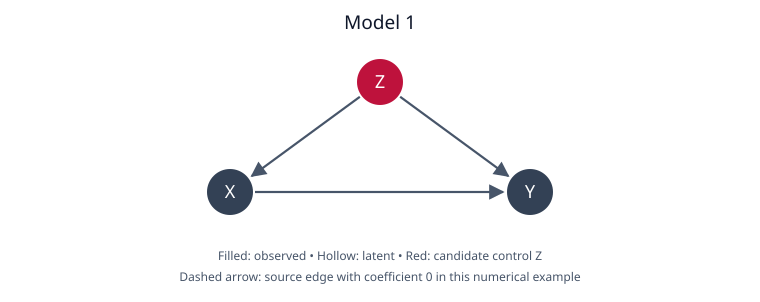

In [ ]:
draw_dag(
    title='Model 1',
    edges=[('x', 'y'), ('z', 'x'), ('z', 'y')],
    positions={'x': (1, 1), 'y': (3, 1), 'z': (2, 2)},
)


### Numerical simulation

Each ε is an independent N(0, 1) disturbance. An already generated variable is reused wherever it appears.

$$
\begin{aligned}
Z &= \varepsilon_{Z} \\
X &= Z + \varepsilon_{X} \\
Y &= X + Z + \varepsilon_{Y}
\end{aligned}
$$

A unit increase in X increases Y directly by 1. Thus the total causal effect is 1.

Compare `Y ~ 1 + X` (population X slope 1.5, due to the covariance between X and Z) with `Y ~ 1 + X + Z` (1).

$X$ and $Z$ share the term $Z$, so $\operatorname{Cov}(X,Z)=\operatorname{Var}(Z)=1$. The two independent terms in $X$ give $\operatorname{Var}(X)=1+1=2$. Using $\operatorname{Cov}(X,\varepsilon_Y)=0$, the unadjusted slope is

$$
\frac{\operatorname{Cov}(X,Y)}{\operatorname{Var}(X)}
=1+\frac{\operatorname{Cov}(X,Z)}{\operatorname{Var}(X)}
=1+\frac{1}{2}=1.5.
$$


In [ ]:
def simulate_confounder(rng: np.random.Generator) -> Data:
    z = rng.standard_normal(N)
    x = z + rng.standard_normal(N)
    y = x + z + rng.standard_normal(N)
    return {"x": x, "y": y, "z": z}


data = simulate_confounder(stream("confounder:example"))
results["1"] = compare(data)


Y ~ 1 + X
  intercept=-0.015474   x= 1.488480
Y ~ 1 + X + Z
  intercept=-0.016363   x= 1.006073   z= 0.987562
Total causal effect from the structural equations: 1



## Model 2 — Good control: block a latent path

Conditioning on Z blocks the path X ← Z ← U → Y. The diagram's edges are X → Y, U → Z, Z → X, U → Y and the latent variable is U.


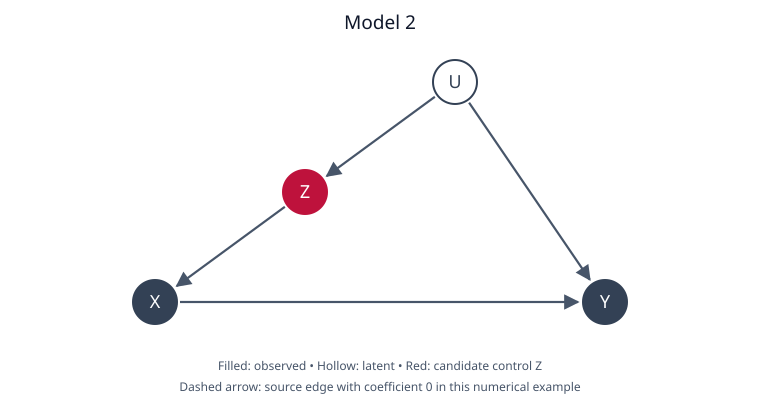

In [ ]:
draw_dag(
    title='Model 2',
    edges=[('x', 'y'), ('u', 'z'), ('z', 'x'), ('u', 'y')],
    positions={'x': (1, 1), 'z': (2, 2), 'u': (3, 3), 'y': (4, 1)},
    latent=['u'],
)


### Numerical simulation

Follows from the above.

$$
\begin{aligned}
U &= \varepsilon_{U} \\
Z &= U + \varepsilon_{Z} \\
X &= Z + \varepsilon_{X} \\
Y &= X + U + \varepsilon_{Y}
\end{aligned}
$$

A unit increase in X increases Y directly by 1. Thus the total causal effect is 1.

Compare `Y ~ 1 + X` (population X slope 1.33333) with `Y ~ 1 + X + Z` (1).

$X$ contains three independent contributions, $U$, $\varepsilon_Z$, and $\varepsilon_X$, so $\operatorname{Var}(X)=1+1+1=3$. Only the shared term $U$ contributes to $\operatorname{Cov}(X,U)=\operatorname{Var}(U)=1$. Using $\operatorname{Cov}(X,\varepsilon_Y)=0$, the unadjusted slope is

$$
\frac{\operatorname{Cov}(X,Y)}{\operatorname{Var}(X)}
=1+\frac{\operatorname{Cov}(X,U)}{\operatorname{Var}(X)}
=1+\frac{1}{3}=\frac{4}{3}.
$$


In [ ]:
def simulate_treatment_cause(rng: np.random.Generator) -> Data:
    u = rng.standard_normal(N)
    z = u + rng.standard_normal(N)
    x = z + rng.standard_normal(N)
    y = x + u + rng.standard_normal(N)
    return {"x": x, "y": y, "z": z}


data = simulate_treatment_cause(stream("treatment_cause:example"))
results["2"] = compare(data)


Y ~ 1 + X
  intercept= 0.034248   x= 1.331274
Y ~ 1 + X + Z
  intercept= 0.023918   x= 0.983036   z= 0.520836
Total causal effect from the structural equations: 1



## Model 3 — Good control: Z need not cause X

Conditioning on Z closes X ← U → Z → Y. A useful control need not be a common cause of both treatment and outcome; in this case, it is only a cause of the outcome. 

The diagram's edges are X → Y, U → Z, U → X, Z → Y and the latent variable is U.


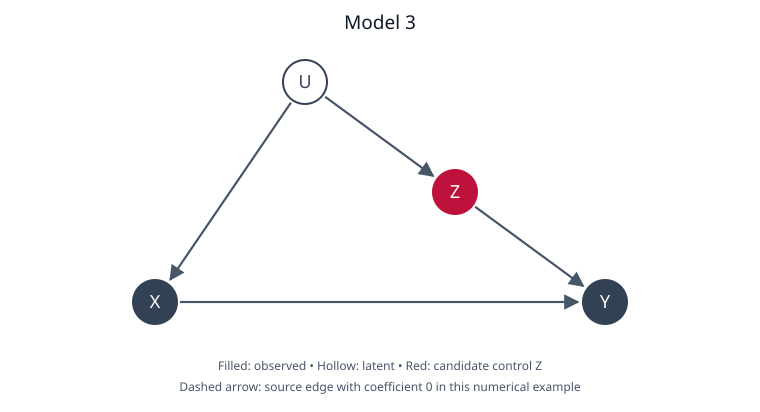

In [ ]:
draw_dag(
    title='Model 3',
    edges=[('x', 'y'), ('u', 'z'), ('u', 'x'), ('z', 'y')],
    positions={'x': (1, 1), 'z': (3, 2), 'u': (2, 3), 'y': (4, 1)},
    latent=['u'],
)


### Numerical simulation

$$
\begin{aligned}
U &= \varepsilon_{U} \\
Z &= U + \varepsilon_{Z} \\
X &= U + \varepsilon_{X} \\
Y &= X + Z + \varepsilon_{Y}
\end{aligned}
$$

A unit increase in X increases Y directly by 1. Thus the total causal effect is 1.

Compare `Y ~ 1 + X` (population X slope 1.5) with `Y ~ 1 + X + Z` (1).

$X$ and $Z$ share the common cause $U$, giving $\operatorname{Cov}(X,Z)=\operatorname{Var}(U)=1$. The two independent terms in $X$ give $\operatorname{Var}(X)=1+1=2$. Using $\operatorname{Cov}(X,\varepsilon_Y)=0$, the unadjusted slope is

$$
\frac{\operatorname{Cov}(X,Y)}{\operatorname{Var}(X)}
=1+\frac{\operatorname{Cov}(X,Z)}{\operatorname{Var}(X)}
=1+\frac{1}{2}=1.5.
$$


In [ ]:
def simulate_outcome_cause(rng: np.random.Generator) -> Data:
    u = rng.standard_normal(N)
    z = u + rng.standard_normal(N)
    x = u + rng.standard_normal(N)
    y = x + z + rng.standard_normal(N)
    return {"x": x, "y": y, "z": z}


data = simulate_outcome_cause(stream("outcome_cause:example"))
results["3"] = compare(data)


Y ~ 1 + X
  intercept= 0.003786   x= 1.499344
Y ~ 1 + X + Z
  intercept= 0.014190   x= 1.003688   z= 0.996593
Total causal effect from the structural equations: 1



## Model 4 — Good control: confounding through a mediator

The path X ← Z → M → Y is noncausal. Adjust for Z while leaving the causal route X → M → Y open. The diagram's edges are X → Y, Z → X, X → M, Z → M, M → Y and there are no latent variables.

The simulation gives the direct edge X → Y a coefficient of 0 in `y = m + ε_y`.


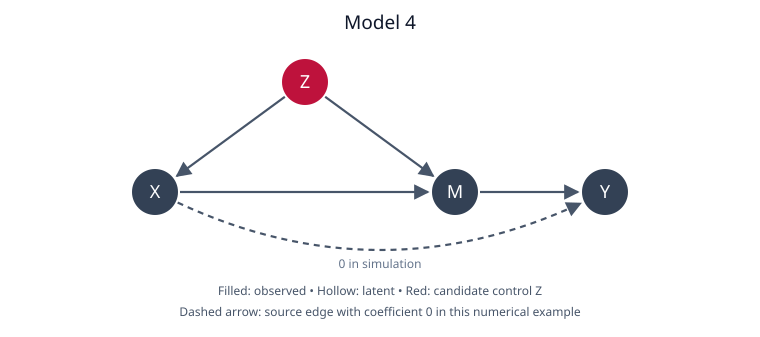

In [ ]:
draw_dag(
    title='Model 4',
    edges=[('x', 'y'), ('z', 'x'), ('x', 'm'), ('z', 'm'), ('m', 'y')],
    positions={'x': (1, 1), 'z': (2, 2), 'm': (3, 1), 'y': (4, 1)},
    zero_edges=[('x', 'y')],
    curved=[('x', 'y')],
)


### Numerical simulation

$$
\begin{aligned}
Z &= \varepsilon_{Z} \\
X &= Z + \varepsilon_{X} \\
M &= X + Z + \varepsilon_{M} \\
Y &= M + \varepsilon_{Y}
\end{aligned}
$$

A unit increase in X increases M by 1 and Y through M by 1 × 1 = 1. Thus the total causal effect is 1.

Compare `Y ~ 1 + X` (population X slope 1.5) with `Y ~ 1 + X + Z` (1).

$X$ and $Z$ share the term $Z$, giving $\operatorname{Cov}(X,Z)=\operatorname{Var}(Z)=1$ and $\operatorname{Var}(X)=1+1=2$. The disturbances in $M$ and $Y$ are independent of $X$, so $\operatorname{Cov}(X,Y)=\operatorname{Cov}(X,M)=\operatorname{Var}(X)+\operatorname{Cov}(X,Z)$. The unadjusted slope is

$$
\frac{\operatorname{Cov}(X,Y)}{\operatorname{Var}(X)}
=\frac{\operatorname{Cov}(X,M)}{\operatorname{Var}(X)}
=1+\frac{\operatorname{Cov}(X,Z)}{\operatorname{Var}(X)}
=1+\frac{1}{2}=1.5.
$$


In [ ]:
def simulate_confounder_of_mediator(rng: np.random.Generator) -> Data:
    z = rng.standard_normal(N)
    x = z + rng.standard_normal(N)
    m = x + z + rng.standard_normal(N)
    y = m + rng.standard_normal(N)
    return {"x": x, "y": y, "z": z}


data = simulate_confounder_of_mediator(stream("confounder_of_mediator:example"))
results["4"] = compare(data)


Y ~ 1 + X
  intercept=-0.020428   x= 1.501424
Y ~ 1 + X + Z
  intercept=-0.011994   x= 1.018520   z= 0.989023
Total causal effect from the structural equations: 1



## Model 5 — Good control: a latent cause of the mediator

Z blocks X ← Z ← U → M → Y. Confounding of X and a mediator can also confound the total effect on Y. The diagram's edges are X → Y, U → Z, Z → X, X → M, U → M, M → Y and the latent variable is U.

The simulation gives the direct edge X → Y a coefficient of 0 in `y = m + ε_y`.


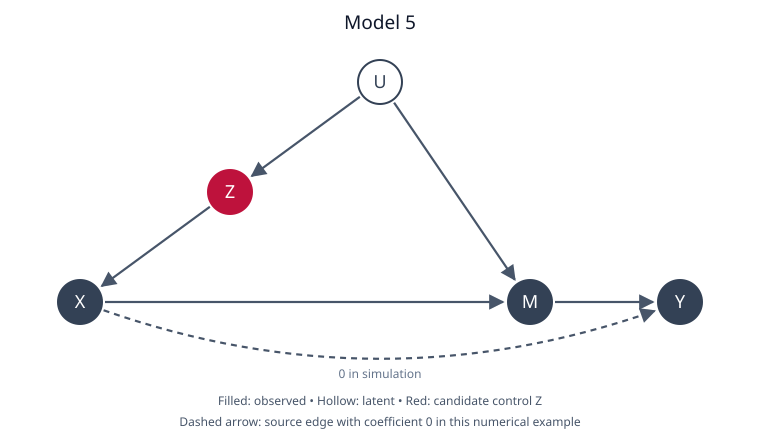

In [ ]:
draw_dag(
    title='Model 5',
    edges=[('x', 'y'), ('u', 'z'), ('z', 'x'), ('x', 'm'), ('u', 'm'), ('m', 'y')],
    positions={'x': (1, 1), 'z': (2, 2), 'u': (3, 3), 'm': (4, 1), 'y': (5, 1)},
    latent=['u'],
    zero_edges=[('x', 'y')],
    curved=[('x', 'y')],
)


### Numerical simulation

$$
\begin{aligned}
U &= \varepsilon_{U} \\
Z &= U + \varepsilon_{Z} \\
X &= Z + \varepsilon_{X} \\
M &= X + U + \varepsilon_{M} \\
Y &= M + \varepsilon_{Y}
\end{aligned}
$$

Compare `Y ~ 1 + X` (population X slope 1.33333) with `Y ~ 1 + X + Z` (1).

$X$ and $Z$ share a term $Z$, giving $\operatorname{Cov}(X,Z)=\operatorname{Var}(Z)=2$ (since now $Z$ is caused by $U$) and $\operatorname{Var}(X)=1+2=3$. Since the disturbances in $M$ and $Y$ are independent of $X$, $\operatorname{Cov}(X,Y)=\operatorname{Cov}(X,M)=\operatorname{Var}(X)+\operatorname{Cov}(X,U)$, such that the unadjusted slope is

$$
\frac{\operatorname{Cov}(X,Y)}{\operatorname{Var}(X)}
=\frac{\operatorname{Cov}(X,M)}{\operatorname{Var}(X)}
=1+\frac{\operatorname{Cov}(X,U)}{\operatorname{Var}(X)}
=1+\frac{1}{3}=1.333.
$$


In [ ]:
def simulate_latent_mediator_confounder(rng: np.random.Generator) -> Data:
    u = rng.standard_normal(N)
    z = u + rng.standard_normal(N)
    x = z + rng.standard_normal(N)
    m = x + u + rng.standard_normal(N)
    y = m + rng.standard_normal(N)
    return {"x": x, "y": y, "z": z}


data = simulate_latent_mediator_confounder(stream("latent_mediator_confounder:example"))
results["5"] = compare(data)


Y ~ 1 + X
  intercept= 0.005855   x= 1.357427
Y ~ 1 + X + Z
  intercept=-0.003318   x= 1.017821   z= 0.505603
Total causal effect from the structural equations: 1



## Model 6 — Good control: block the path before the mediator

Z blocks X ← U → Z → M → Y without conditioning on M itself. The diagram's edges are X → Y, U → Z, Z → M, X → M, U → X, M → Y and the latent variable is U.

The simulation gives the direct edge X → Y a coefficient of 0 in `y = m + ε_y`.


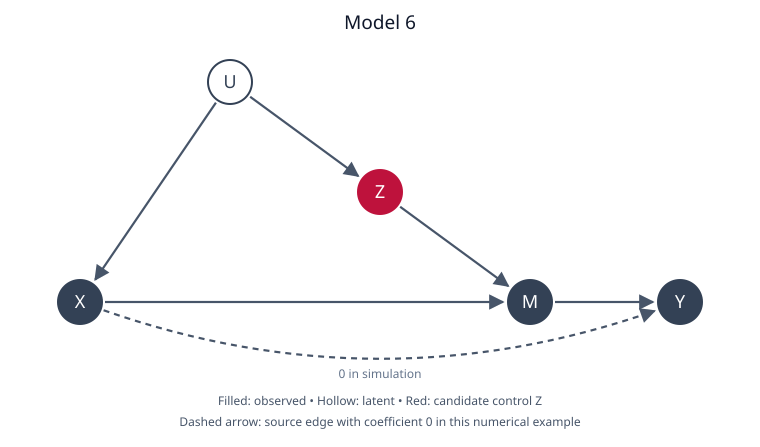

In [ ]:
draw_dag(
    title='Model 6',
    edges=[('x', 'y'), ('u', 'z'), ('z', 'm'), ('x', 'm'), ('u', 'x'), ('m', 'y')],
    positions={'x': (1, 1), 'z': (3, 2), 'u': (2, 3), 'm': (4, 1), 'y': (5, 1)},
    latent=['u'],
    zero_edges=[('x', 'y')],
    curved=[('x', 'y')],
)


### Numerical simulation

$$
\begin{aligned}
U &= \varepsilon_{U} \\
Z &= U + \varepsilon_{Z} \\
X &= U + \varepsilon_{X} \\
M &= X + Z + \varepsilon_{M} \\
Y &= M + \varepsilon_{Y}
\end{aligned}
$$

Compare `Y ~ 1 + X` (population X slope 1.5) with `Y ~ 1 + X + Z` (1).

$X$ and $Z$ share the common cause $U$, giving $\operatorname{Cov}(X,Z)=\operatorname{Var}(U)=1$ and $\operatorname{Var}(X)=1+1=2$. Since the disturbances in $M$ and $Y$ are independent of $X$, $\operatorname{Cov}(X,Y)=\operatorname{Cov}(X,M)=\operatorname{Var}(X)+\operatorname{Cov}(X,Z)$, so the unadjusted slope is

$$
\frac{\operatorname{Cov}(X,Y)}{\operatorname{Var}(X)}
=\frac{\operatorname{Cov}(X,M)}{\operatorname{Var}(X)}
=1+\frac{\operatorname{Cov}(X,Z)}{\operatorname{Var}(X)}
=1+\frac{1}{2}=1.5.
$$


In [ ]:
def simulate_mediator_cause(rng: np.random.Generator) -> Data:
    u = rng.standard_normal(N)
    z = u + rng.standard_normal(N)
    x = u + rng.standard_normal(N)
    m = x + z + rng.standard_normal(N)
    y = m + rng.standard_normal(N)
    return {"x": x, "y": y, "z": z}


data = simulate_mediator_cause(stream("mediator_cause:example"))
results["6"] = compare(data)


Y ~ 1 + X
  intercept= 0.020508   x= 1.490129
Y ~ 1 + X + Z
  intercept= 0.021412   x= 0.992839   z= 0.986964
Total causal effect from the structural equations: 1



## Model 7 — Bad control: M-bias

The first regression leaves the collider path X ← U₁ → Z ← U₂ → Y closed. Conditioning on Z opens it. Being measured before treatment does not make Z a good control. The diagram's edges are X → Y, U₁ → X, U₁ → Z, U₂ → Z, U₂ → Y and the latent variables are U₁ and U₂.


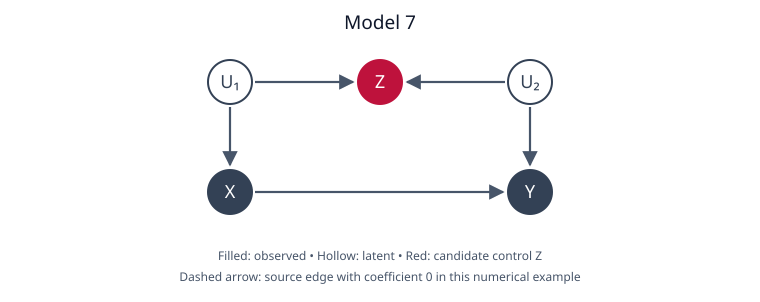

In [ ]:
draw_dag(
    title='Model 7',
    edges=[('x', 'y'), ('u1', 'x'), ('u1', 'z'), ('u2', 'z'), ('u2', 'y')],
    positions={'x': (1, 1), 'u1': (1, 2), 'z': (2, 2), 'u2': (3, 2), 'y': (3, 1)},
    latent=['u1', 'u2'],
)


### Numerical simulation

$$
\begin{aligned}
U_1 &= \varepsilon_{U_1} \\
U_2 &= \varepsilon_{U_2} \\
Z &= U_1 + U_2 + \varepsilon_{Z} \\
X &= U_1 + \varepsilon_{X} \\
Y &= X - 4\,U_2 + \varepsilon_{Y}
\end{aligned}
$$

Compare `Y ~ 1 + X` (population X slope 1) with `Y ~ 1 + X + Z` (1.8).

$X$ depends on $U_1$ and its own disturbance, both independent of $U_2$, so $\operatorname{Var}(X)=1+1=2$ and $\operatorname{Cov}(X,U_2)=0$. The disturbance in $Y$ is also independent of $X$, giving $\operatorname{Cov}(X,Y)=\operatorname{Var}(X)-4\operatorname{Cov}(X,U_2)$. The unadjusted slope is

$$
\frac{\operatorname{Cov}(X,Y)}{\operatorname{Var}(X)}
=1-4\frac{\operatorname{Cov}(X,U_2)}{\operatorname{Var}(X)}
=1-0=1.
$$


In [ ]:
def simulate_pre_treatment_collider(rng: np.random.Generator) -> Data:
    u1 = rng.standard_normal(N)
    u2 = rng.standard_normal(N)
    z = u1 + u2 + rng.standard_normal(N)
    x = u1 + rng.standard_normal(N)
    y = x - 4 * u2 + rng.standard_normal(N)
    return {"x": x, "y": y, "z": z}


data = simulate_pre_treatment_collider(stream("pre_treatment_collider:example"))
results["7"] = compare(data)


Y ~ 1 + X
  intercept=-0.057280   x= 1.007549
Y ~ 1 + X + Z
  intercept=-0.036265   x= 1.831790   z=-1.621573
Total causal effect from the structural equations: 1



## Model 8 — Neutral for bias, helpful for precision

X and Z are independent causes of Y. Adjusting for Z removes outcome variation unrelated to X, improving precision while preserving the causal effect. The diagram's edges are X → Y, Z → Y and there are no latent variables.


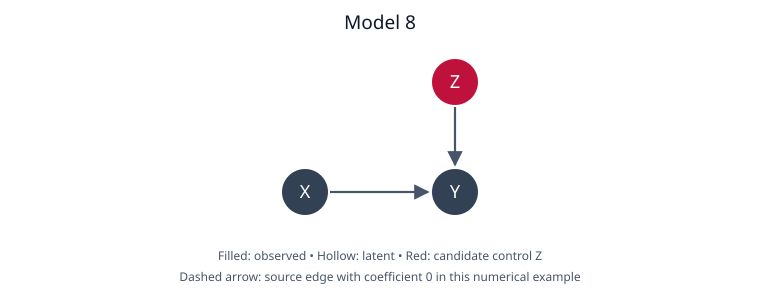

In [ ]:
draw_dag(
    title='Model 8',
    edges=[('x', 'y'), ('z', 'y')],
    positions={'x': (1, 1), 'z': (2, 2), 'y': (2, 1)},
)


### Numerical simulation

$$
\begin{aligned}
Z &= \varepsilon_{Z} \\
X &= \varepsilon_{X} \\
Y &= X + 2\,Z + \varepsilon_{Y}
\end{aligned}
$$

Compare `Y ~ 1 + X` (population X slope 1) with `Y ~ 1 + X + Z` (1).


In [ ]:
def simulate_independent_outcome_predictor(rng: np.random.Generator) -> Data:
    z = rng.standard_normal(N)
    x = rng.standard_normal(N)
    y = x + 2 * z + rng.standard_normal(N)
    return {"x": x, "y": y, "z": z}


data = simulate_independent_outcome_predictor(stream("independent_outcome_predictor:example"))
results["8"] = compare(data)


Y ~ 1 + X
  intercept=-0.028342   x= 1.024917
Y ~ 1 + X + Z
  intercept= 0.001221   x= 1.005729   z= 1.988552
Total causal effect from the structural equations: 1



### Repeated simulation: precision

For the linear models in the examples, with constant error variance, the large-sample sampling variance and SD of the slope satisfy

$$
\operatorname{Var}(\hat\beta_X)\approx\frac{\sigma_{\mathrm{res}}^2}{nV_X},
\qquad
\operatorname{SD}(\hat\beta_X)\approx\sqrt{\frac{\sigma_{\mathrm{res}}^2}{nV_X}}.
$$

with $\sigma_{\mathrm{res}}^2$ is the variance of the unexplained part of $Y$, and $V_X$ is the variation in $X$ available to estimate its coefficient. Without adjustment, $V_X=\operatorname{Var}(X)$. With adjustment, $V_X$ is the variance left after removing the linear prediction of $X$ from $Z$. For fixed outcome noise and sample size, more available variation in $X$ means a smaller sampling SD.

The adjusted estimator should have a smaller sampling standard deviation (SD).

In Model 8, $X$, $Z$, and $\varepsilon_Y$ are independent and each has variance 1. Without adjustment, the unexplained part of $Y$ is $2Z+\varepsilon_Y$, whose variance is $4+1=5$. Random associations between $X$ and $Z$ in each sample make the estimated $X$ slope fluctuate.

Including $Z$ accounts for its contribution to $Y$, leaving only $\varepsilon_Y$, with variance 1. Because $Z$ is independent of $X$, adjustment preserves the available variation in $X$ at the population level.

In Model 8, $V_X=1$ in both regressions, while $\sigma_{\mathrm{res}}^2$ decreases from 5 to 1. Substitution gives

$$
\operatorname{SD}(\hat\beta_{X,\text{unadjusted}})\approx\sqrt{\frac{5}{n\cdot1}},
\qquad
\operatorname{SD}(\hat\beta_{X,\text{adjusted}})\approx\sqrt{\frac{1}{n\cdot1}}.
$$

Thus, across repeated datasets, the adjusted slope standard deviation has about $1/\sqrt{5}\approx0.447$ times the sampling standard deviation. 

Each replication generates fresh data, fits both models to the same observations, and retains the X slopes.
The sampling SD describes estimator variability across datasets. `MCSE(mean) = SD / sqrt(R)` describes uncertainty in the reported Monte Carlo mean.


In [ ]:
precision_results["8"] = precision(simulate_independent_outcome_predictor, stream("independent_outcome_predictor:precision"))


1,000 paired replications; n=5,000
Estimator            Mean       Bias   Sampling SD   MCSE(mean)
Unadjusted       1.000044   0.000044      0.031381     0.000992
Adjusted         0.999954  -0.000046      0.014164     0.000448
Adjusted/unadjusted sampling SD: 0.4513
Asymptotic SD ratio estimated from data: 0.4473
Elapsed: 0.5 seconds


## Model 9 — Neutral for bias, harmful for precision

Z predicts X but has no separate route to Y. Conditioning on Z reduces the usable variation in X and increases the sampling SD. The diagram's edges are X → Y, Z → X and there are no latent variables.


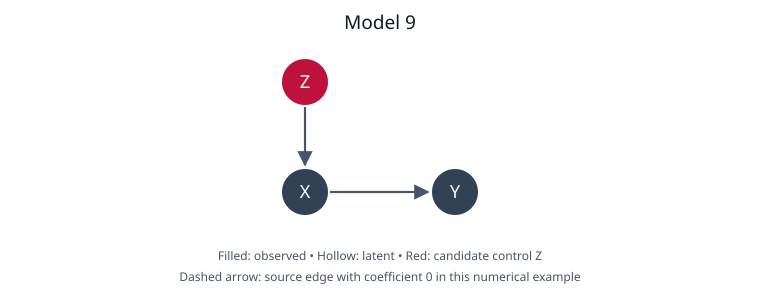

In [ ]:
draw_dag(
    title='Model 9',
    edges=[('x', 'y'), ('z', 'x')],
    positions={'x': (1, 1), 'z': (1, 2), 'y': (2, 1)},
)


### Numerical simulation

$$
\begin{aligned}
Z &= \varepsilon_{Z} \\
X &= 2\,Z + \varepsilon_{X} \\
Y &= X + 2\,\varepsilon_{Y}
\end{aligned}
$$

Compare `Y ~ 1 + X` (population X slope 1) with `Y ~ 1 + X + Z` (1).


In [ ]:
def simulate_treatment_predictor(rng: np.random.Generator) -> Data:
    z = rng.standard_normal(N)
    x = 2 * z + rng.standard_normal(N)
    y = x + 2 * rng.standard_normal(N)
    return {"x": x, "y": y, "z": z}


data = simulate_treatment_predictor(stream("treatment_predictor:example"))
results["9"] = compare(data)


Y ~ 1 + X
  intercept= 0.057436   x= 0.996863
Y ~ 1 + X + Z
  intercept= 0.057659   x= 1.041319   z=-0.111555
Total causal effect from the structural equations: 1



### Repeated simulation: precision

The adjusted estimator should have a larger sampling SD.

In Model 9, $Z$, $\varepsilon_X$, and $\varepsilon_Y$ are independent and each has variance 1. Without adjustment, the variation in $X$ comes from $2Z+\varepsilon_X$, whose variance is $4+1=5$. The unexplained part of $Y$ is $2\varepsilon_Y$, with variance 4.

Including $Z$ accounts for the $2Z$ contribution to $X$, leaving only $\varepsilon_X$, with variance 1, to estimate the coefficient of $X$. The unexplained variation in $Y$ still has variance 4. Estimating the slope from less variation in $X$ with the same outcome noise increases its sampling SD.

Using the above formula, $\operatorname{SD}(\hat\beta_X)\approx\sqrt{\sigma_{\mathrm{res}}^2/(nV_X)}$, together with:

- $\sigma_{\mathrm{res}}^2=4$ for both regressions. 
- Without adjustment, $V_X=\operatorname{Var}(X)=5$. 
- Adjusting for $Z$ leaves $V_X=\operatorname{Var}(\varepsilon_X)=1$. 

Therefore yielding

$$
\operatorname{SD}(\hat\beta_{X,\text{unadjusted}})\approx\sqrt{\frac{4}{n\cdot5}},
\qquad
\operatorname{SD}(\hat\beta_{X,\text{adjusted}})\approx\sqrt{\frac{4}{n\cdot1}}.
$$

Thus, across repeated datasets, the adjusted slope has about $\sqrt{5}\approx2.236$ times the sampling standard deviation of the unadjusted slope.

Each replication generates fresh data, fits both models to the same observations, and retains the X slopes.
The sampling SD describes estimator variability across datasets. `MCSE(mean) = SD / sqrt(R)` describes uncertainty in the reported Monte Carlo mean.


In [ ]:
precision_results["9"] = precision(simulate_treatment_predictor, stream("treatment_predictor:precision"))


1,000 paired replications; n=5,000
Estimator            Mean       Bias   Sampling SD   MCSE(mean)
Unadjusted       1.000145   0.000145      0.013007     0.000411
Adjusted         0.999883  -0.000117      0.028099     0.000889
Adjusted/unadjusted sampling SD: 2.1603
Asymptotic SD ratio estimated from data: 2.2355
Elapsed: 0.5 seconds


## Model 10 — Bad control: bias amplification

U confounds X and Y. Conditioning on Z leaves that confounding and removes variation in X unrelated to U, amplifying the bias in this linear model. The diagram's edges are X → Y, U → X, U → Y, Z → X and the latent variable is U.


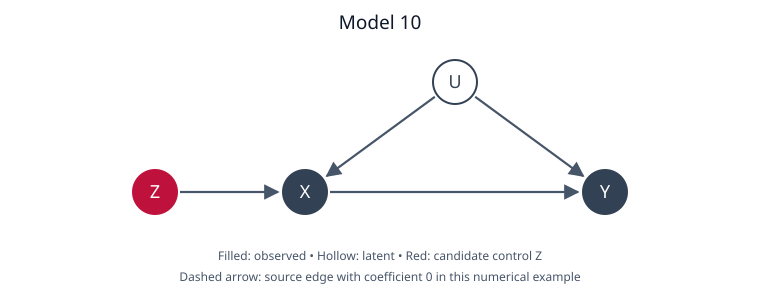

In [ ]:
draw_dag(
    title='Model 10',
    edges=[('x', 'y'), ('u', 'x'), ('u', 'y'), ('z', 'x')],
    positions={'z': (1, 1), 'x': (2, 1), 'u': (3, 2), 'y': (4, 1)},
    latent=['u'],
)


### Numerical simulation

$$
\begin{aligned}
Z &= \varepsilon_{Z} \\
U &= \varepsilon_{U} \\
X &= 2\,Z + U + \varepsilon_{X} \\
Y &= X + 2\,U + \varepsilon_{Y}
\end{aligned}
$$

Compare `Y ~ 1 + X` (population X slope 1.33333) with `Y ~ 1 + X + Z` (2).

The unobserved $U$ causes confounding. Without adjustment, $X$ has variance $4+1+1=6$ and $\operatorname{Cov}(X,U)=1$. Its population slope is

$$
\frac{\operatorname{Cov}(X,Y)}{\operatorname{Var}(X)}
=1+\frac{2\operatorname{Cov}(X,U)}{\operatorname{Var}(X)}
=1+\frac{2}{6}=\frac{4}{3}.
$$

Controlling for $Z$ removes the $2Z$ component of $X$. The remaining variation is $U+\varepsilon_X$, with variance 2. Its covariance with $U$ is still 1, so the adjusted population slope becomes

$$
\beta_{X,\text{adjusted}}
=1+\frac{2\operatorname{Cov}(U+\varepsilon_X,U)}{\operatorname{Var}(U+\varepsilon_X)}
=1+\frac{2}{2}=2.
$$

The bias (e.g, the second term) increases to 1. Adjustment removes variation in $X$ that is independent of $U$, making $U$ responsible for a larger proportion of the variation used to estimate $X$'s coefficient.


In [ ]:
def simulate_bias_amplifier(rng: np.random.Generator) -> Data:
    z = rng.standard_normal(N)
    u = rng.standard_normal(N)
    x = 2 * z + u + rng.standard_normal(N)
    y = x + 2 * u + rng.standard_normal(N)
    return {"x": x, "y": y, "z": z}


data = simulate_bias_amplifier(stream("bias_amplifier:example"))
results["10"] = compare(data)


Y ~ 1 + X
  intercept= 0.035639   x= 1.319286
Y ~ 1 + X + Z
  intercept= 0.013641   x= 1.984092   z=-1.982890
Total causal effect from the structural equations: 1



## Model 11 — Bad control for the total effect: a mediator

The entire effect travels along X → Z → Y. Adjusting for Z blocks it. The diagram's edges are X → Z, Z → Y and there are no latent variables.


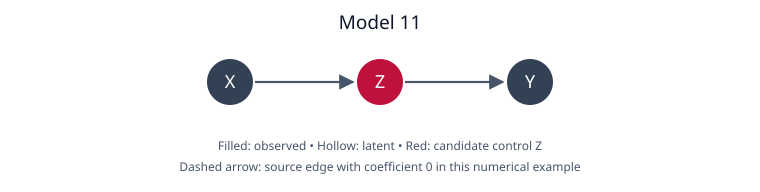

In [ ]:
draw_dag(
    title='Model 11',
    edges=[('x', 'z'), ('z', 'y')],
    positions={'x': (1, 1), 'z': (2, 1), 'y': (3, 1)},
)


### Numerical simulation

$$
\begin{aligned}
X &= \varepsilon_{X} \\
Z &= X + \varepsilon_{Z} \\
Y &= Z + \varepsilon_{Y}
\end{aligned}
$$

Compare `Y ~ 1 + X` (population X slope 1) with `Y ~ 1 + X + Z` (0). The variation of Y is now explained by Z rather than by X.


In [ ]:
def simulate_mediator(rng: np.random.Generator) -> Data:
    x = rng.standard_normal(N)
    z = x + rng.standard_normal(N)
    y = z + rng.standard_normal(N)
    return {"x": x, "y": y, "z": z}


data = simulate_mediator(stream("mediator:example"))
results["11"] = compare(data)


Y ~ 1 + X
  intercept= 0.016668   x= 0.985941
Y ~ 1 + X + Z
  intercept=-0.007286   x= 0.026498   z= 0.962084
Total causal effect from the structural equations: 1



## Model 12 — Bad control: a mediator’s descendant

Z is an effect of M, not a mediator on the X → M → Y path. Conditioning on this noisy proxy for M still biases the total-effect estimate. 

The diagram's edges are X → M, M → Z, M → Y and there are no latent variables.


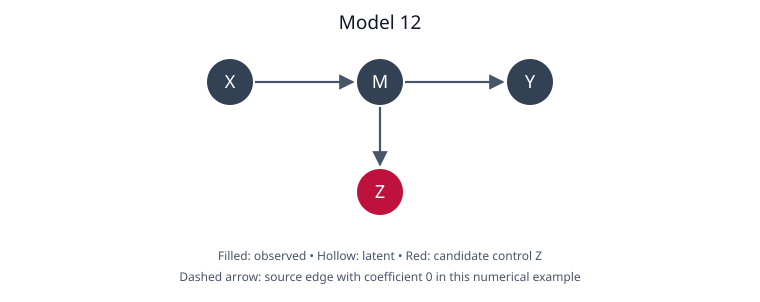

In [ ]:
draw_dag(
    title='Model 12',
    edges=[('x', 'm'), ('m', 'z'), ('m', 'y')],
    positions={'x': (1, 2), 'm': (2, 2), 'z': (2, 1), 'y': (3, 2)},
)


### Numerical simulation

$$
\begin{aligned}
X &= \varepsilon_{X} \\
M &= X + \varepsilon_{M} \\
Z &= M + \varepsilon_{Z} \\
Y &= M + \varepsilon_{Y}
\end{aligned}
$$

Compare `Y ~ 1 + X` (population X slope 1) with `Y ~ 1 + X + Z` (0.5). Adjusting for Z accounts partially for the effect that X has on Y through M (since Z and Y have the same cause), such that the regression coefficient of each variable is 0.5.


In [ ]:
def simulate_mediator_proxy(rng: np.random.Generator) -> Data:
    x = rng.standard_normal(N)
    m = x + rng.standard_normal(N)
    z = m + rng.standard_normal(N)
    y = m + rng.standard_normal(N)
    return {"x": x, "y": y, "z": z}


data = simulate_mediator_proxy(stream("mediator_proxy:example"))
results["12"] = compare(data)


Y ~ 1 + X
  intercept=-0.014575   x= 1.025662
Y ~ 1 + X + Z
  intercept=-0.012586   x= 0.510283   z= 0.509705
Total causal effect from the structural equations: 1



## Variation of Model 11 — Total versus direct effects

U confounds Z and Y, but does not confound the total effect of X. Adjusting for Z opens X → Z ← U → Y. The adjusted slope tends to −1/2, which is neither the total effect (1) nor the controlled direct effect (0). 

The diagram's edges are X → Z, Z → Y, U → Z, U → Y and the latent variable is U.


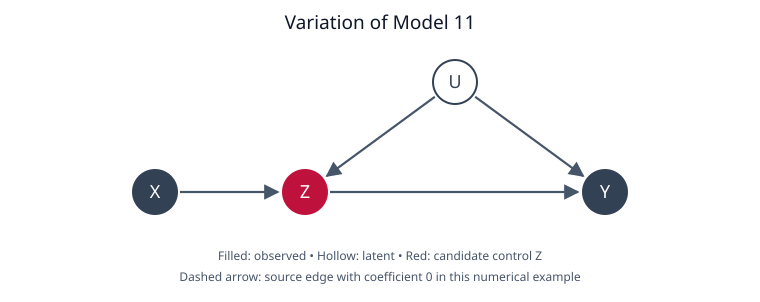

In [ ]:
draw_dag(
    title='Variation of Model 11',
    edges=[('x', 'z'), ('z', 'y'), ('u', 'z'), ('u', 'y')],
    positions={'x': (1, 1), 'z': (2, 1), 'u': (3, 2), 'y': (4, 1)},
    latent=['u'],
)


### Numerical simulation

$$
\begin{aligned}
X &= \varepsilon_{X} \\
U &= \varepsilon_{U} \\
Z &= X + U + \varepsilon_{Z} \\
Y &= Z + U + \varepsilon_{Y}
\end{aligned}
$$

Compare `Y ~ 1 + X` (population X slope 1) with `Y ~ 1 + X + Z` (-0.5).


In [ ]:
def simulate_confounded_mediator(rng: np.random.Generator) -> Data:
    x = rng.standard_normal(N)
    u = rng.standard_normal(N)
    z = x + u + rng.standard_normal(N)
    y = z + u + rng.standard_normal(N)
    return {"x": x, "y": y, "z": z}


data = simulate_confounded_mediator(stream("confounded_mediator:example"))
results["11v"] = compare(data)


Y ~ 1 + X
  intercept=-0.013760   x= 0.973746
Y ~ 1 + X + Z
  intercept= 0.008047   x=-0.524513   z= 1.496605
Total causal effect from the structural equations: 1



## Model 13 — Neutral for bias, helpful for precision through M

Z causes M and consequently Y and is independent of X. Adjusting for Z removes outcome variation unrelated to X; compare this with Model 12, where Z is an effect of M. 

The diagram's edges are X → Y, X → M, Z → M, M → Y and there are no latent variables.

The simulation gives X → M a coefficient of 0 in `m = 2*z + ε_m`. Adding an X term would change the total effect.


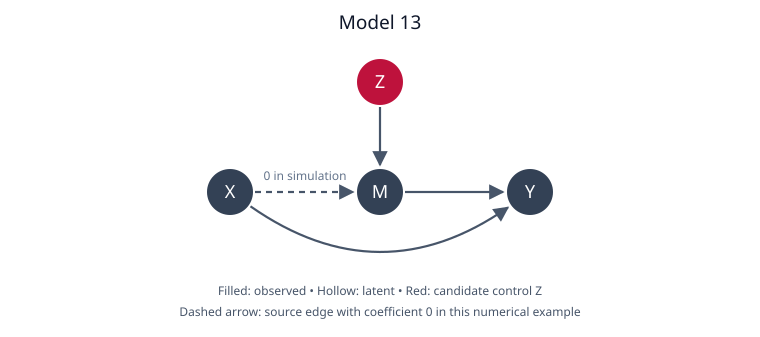

In [ ]:
draw_dag(
    title='Model 13',
    edges=[('x', 'y'), ('x', 'm'), ('z', 'm'), ('m', 'y')],
    positions={'x': (1, 1), 'z': (2, 2), 'm': (2, 1), 'y': (3, 1)},
    zero_edges=[('x', 'm')],
    curved=[('x', 'y')],
)


### Numerical simulation

$$
\begin{aligned}
Z &= \varepsilon_{Z} \\
X &= \varepsilon_{X} \\
M &= 2\,Z + \varepsilon_{M} \\
Y &= X + 2\,M + \varepsilon_{Y}
\end{aligned}
$$

A unit increase in X increases Y directly by 1. Thus the total causal effect is 1.

Compare `Y ~ 1 + X` (population X slope 1) with `Y ~ 1 + X + Z` (1).


In [ ]:
def simulate_independent_mediator_cause(rng: np.random.Generator) -> Data:
    z = rng.standard_normal(N)
    x = rng.standard_normal(N)
    m = 2 * z + rng.standard_normal(N)
    y = x + 2 * m + rng.standard_normal(N)
    return {"x": x, "y": y, "z": z}


data = simulate_independent_mediator_cause(stream("independent_mediator_cause:example"))
results["13"] = compare(data)


Y ~ 1 + X
  intercept=-0.067323   x= 1.090523
Y ~ 1 + X + Z
  intercept= 0.024507   x= 1.026639   z= 4.020655
Total causal effect from the structural equations: 1



### Repeated simulation: precision

Without adjustment, the unexplained part of $Y$ is $4Z+2\varepsilon_M+\varepsilon_Y$. These independent terms give a residual variance of $16+4+1=21$. Controlling for $Z$ removes $4Z$, reducing the residual variance to $4+1=5$.

The large-sample standard deviations are then given by

$$
\operatorname{SD}(\hat\beta_{X,\text{unadjusted}})\approx\sqrt{\frac{21}{n\cdot1}},
\qquad
\operatorname{SD}(\hat\beta_{X,\text{adjusted}})\approx\sqrt{\frac{5}{n\cdot1}}.
$$

The adjusted estimator has about $\sqrt{5/21}\approx0.488$ times the sampling standard deviation of the unadjusted estimator.


In [ ]:
precision_results["13"] = precision(simulate_independent_mediator_cause, stream("independent_mediator_cause:precision"))


1,000 paired replications; n=5,000
Estimator            Mean       Bias   Sampling SD   MCSE(mean)
Unadjusted       0.999328  -0.000672      0.065111     0.002059
Adjusted         1.001322   0.001322      0.032218     0.001019
Adjusted/unadjusted sampling SD: 0.4948
Asymptotic SD ratio estimated from data: 0.4880
Elapsed: 0.5 seconds


## Model 14 — A post-treatment control can be neutral for bias

Z is an effect of X with no separate connection to Y. Adjustment leaves the population coefficient unchanged, but reduces precision.

The diagram's edges are X → Y, X → Z and there are no latent variables.


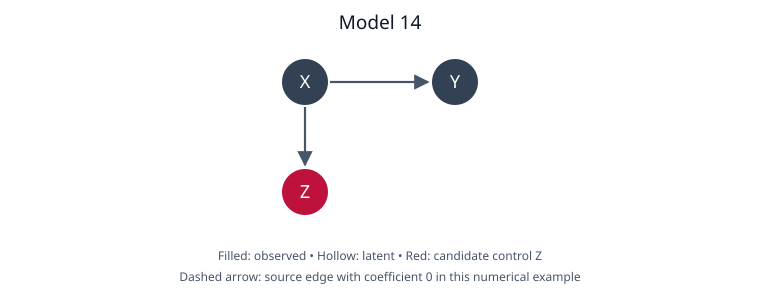

In [ ]:
draw_dag(
    title='Model 14',
    edges=[('x', 'y'), ('x', 'z')],
    positions={'x': (1, 2), 'z': (1, 1), 'y': (2, 2)},
)


### Numerical simulation

$$
\begin{aligned}
X &= \varepsilon_{X} \\
Z &= 2\,X + \varepsilon_{Z} \\
Y &= X + 2\,\varepsilon_{Y}
\end{aligned}
$$

Compare `Y ~ 1 + X` (population X slope 1) with `Y ~ 1 + X + Z` (1).


In [ ]:
def simulate_treatment_descendant(rng: np.random.Generator) -> Data:
    x = rng.standard_normal(N)
    z = 2 * x + rng.standard_normal(N)
    y = x + 2 * rng.standard_normal(N)
    return {"x": x, "y": y, "z": z}


data = simulate_treatment_descendant(stream("treatment_descendant:example"))
results["14"] = compare(data)


Y ~ 1 + X
  intercept=-0.030267   x= 0.983106
Y ~ 1 + X + Z
  intercept=-0.030216   x= 0.968416   z= 0.007371
Total causal effect from the structural equations: 1



### Repeated simulation: precision

Without adjustment, $X$ has variance 1 and the unexplained part of $Y$ is $2\varepsilon_Y$, with variance 4. Controlling for $Z$ leaves this outcome noise unchanged but reduces the available variation in $X$. Since $\operatorname{Var}(Z)=4+1=5$ and $\operatorname{Cov}(X,Z)=2$, the variance remaining after removing the linear prediction of $X$ from $Z$ is

$$
V_{X,\text{adjusted}}
=\operatorname{Var}(X)-\frac{\operatorname{Cov}(X,Z)^2}{\operatorname{Var}(Z)}
=1-\frac{2^2}{5}=\frac{1}{5}.
$$

The large-sample standard deviations are then given by

$$
\operatorname{SD}(\hat\beta_{X,\text{unadjusted}})\approx\sqrt{\frac{4}{n\cdot1}},
\qquad
\operatorname{SD}(\hat\beta_{X,\text{adjusted}})\approx\sqrt{\frac{4}{n\cdot(1/5)}}=\sqrt{\frac{20}{n}}.
$$

The adjusted estimator has about $\sqrt{5}\approx2.236$ times the sampling standard deviation of the unadjusted estimator.


In [ ]:
precision_results["14"] = precision(simulate_treatment_descendant, stream("treatment_descendant:precision"))


1,000 paired replications; n=5,000
Estimator            Mean       Bias   Sampling SD   MCSE(mean)
Unadjusted       0.998302  -0.001698      0.029108     0.000920
Adjusted         1.000727   0.000727      0.064786     0.002049
Adjusted/unadjusted sampling SD: 2.2257
Asymptotic SD ratio estimated from data: 2.2355
Elapsed: 0.5 seconds


## Model 15 — Z helps after conditioning on W

Conditioning on W opens X → Z → W ← U → Y. Additional adjustment for Z closes this noncausal route. The first fit is already conditioned on W.

The diagram's edges are X → Y, X → Z, Z → W, U → W, U → Y and the latent variable is U.


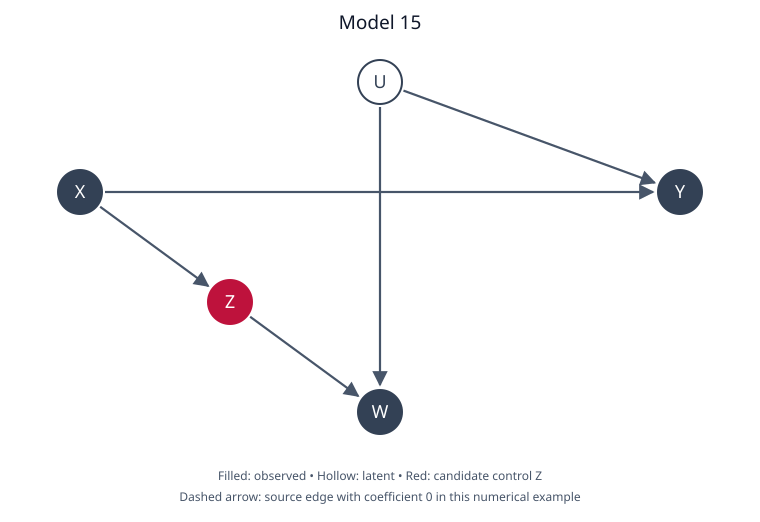

In [ ]:
draw_dag(
    title='Model 15',
    edges=[('x', 'y'), ('x', 'z'), ('z', 'w'), ('u', 'w'), ('u', 'y')],
    positions={'x': (1, 3), 'z': (2, 2), 'w': (3, 1), 'u': (3, 4), 'y': (5, 3)},
    latent=['u'],
)


### Numerical simulation

$$
\begin{aligned}
X &= \varepsilon_{X} \\
U &= \varepsilon_{U} \\
Z &= X + \varepsilon_{Z} \\
W &= Z + U + \varepsilon_{W} \\
Y &= X - 2\,U + \varepsilon_{Y}
\end{aligned}
$$

Compare `Y ~ 1 + X + W` (population X slope 1.66667) with `Y ~ 1 + X + Z + W` (1).

$W$ contains four contributions, $X$, $\varepsilon_Z$, $U$, and $\varepsilon_W$, so $\operatorname{Var}(W)=4$. Since $\operatorname{Var}(X)=1$, $\operatorname{Cov}(X,W)=1$, and $\operatorname{Cov}(X,Y)=1$ and $\operatorname{Cov}(Y,W)=\operatorname{Var}(X)-2\operatorname{Var}(U)=1-2=-1$. 

Conditioning on $W$ alone removes its linear contribution from both $X$ and $Y$, resulting on the adjusted $X$ slope:

$$
\beta_{X\mid W}
=\frac{\operatorname{Cov}(X,Y)-\operatorname{Cov}(X,W)\operatorname{Cov}(Y,W)/\operatorname{Var}(W)}
{\operatorname{Var}(X)-\operatorname{Cov}(X,W)^2/\operatorname{Var}(W)}
=\frac{1-(1)(-1)/4}{1-1^2/4}
=\frac{5/4}{3/4}=\frac{5}{3}\approx1.66667.
$$


In [ ]:
def simulate_selection_collider(rng: np.random.Generator) -> Data:
    x = rng.standard_normal(N)
    u = rng.standard_normal(N)
    z = x + rng.standard_normal(N)
    w = z + u + rng.standard_normal(N)
    y = x - 2 * u + rng.standard_normal(N)
    return {"x": x, "y": y, "z": z, "w": w}


data = simulate_selection_collider(stream("selection_collider:example"))
results["15"] = compare(data, baseline_controls=("w",))
print("Baseline Y ~ 1 + X, before conditioning on W:", ols(data["y"], x=data["x"]))


Y ~ 1 + X + W
  intercept= 0.018441   x= 1.709893   w=-0.671665
Y ~ 1 + X + W + Z
  intercept= 0.016807   x= 1.018636   w=-1.010784   z= 1.022511
Total causal effect from the structural equations: 1

Baseline Y ~ 1 + X, before conditioning on W: {'intercept': 0.01844030150931474, 'x': 1.0445895014852529}


## Model 16 — Bad control: collider stratification

Conditioning on Z opens X → Z ← U → Y. The negative change is large enough that the adjusted slope tends to zero despite a true total effect of 1. 

The diagram's edges are X → Y, X → Z, U → Z, U → Y and the latent variable is U.


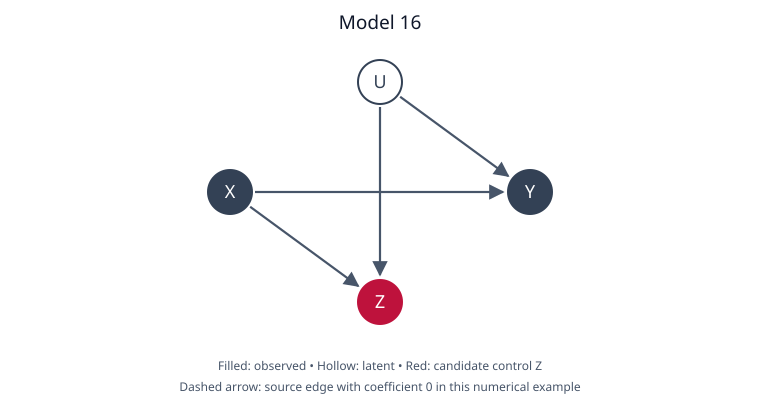

In [ ]:
draw_dag(
    title='Model 16',
    edges=[('x', 'y'), ('x', 'z'), ('u', 'z'), ('u', 'y')],
    positions={'x': (1, 3), 'z': (2, 2), 'u': (2, 4), 'y': (3, 3)},
    latent=['u'],
)


### Numerical simulation

$$
\begin{aligned}
X &= \varepsilon_{X} \\
U &= \varepsilon_{U} \\
Z &= X + U +  \varepsilon_{Z} \\
Y &= X + 2\,U + \varepsilon_{Y}
\end{aligned}
$$

A unit increase in X increases Y directly by 1. Thus the total causal effect is 1.

Compare `Y ~ 1 + X` (population X slope 1) with `Y ~ 1 + X + Z` (0).


In [ ]:
def simulate_treatment_collider(rng: np.random.Generator) -> Data:
    x = rng.standard_normal(N)
    u = rng.standard_normal(N)
    z = x + u + rng.standard_normal(N)
    y = x + 2 * u + rng.standard_normal(N)
    return {"x": x, "y": y, "z": z}


data = simulate_treatment_collider(stream("treatment_collider:example"))
results["16"] = compare(data)


Y ~ 1 + X
  intercept=-0.033760   x= 1.016143
Y ~ 1 + X + Z
  intercept= 0.006090   x=-0.009443   z= 1.000037
Total causal effect from the structural equations: 1



## Model 17 — Bad control: a common effect of X and Y

Conditioning on the collider X → Z ← Y induces bias. This is because, once Z is held fixed, a larger value of X implies a smaller value of $\varepsilon_{Y} + \varepsilon_{Z}$, thereby reducing the correlation of X with Y.

The diagram's edges are X → Y, X → Z, Y → Z and there are no latent variables.


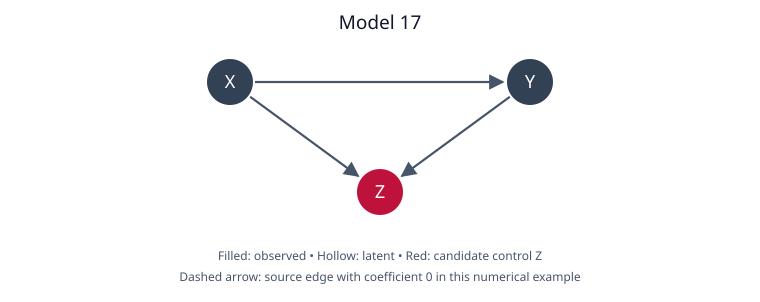

In [ ]:
draw_dag(
    title='Model 17',
    edges=[('x', 'y'), ('x', 'z'), ('y', 'z')],
    positions={'x': (1, 2), 'z': (2, 1), 'y': (3, 2)},
)


### Numerical simulation

$$
\begin{aligned}
X &= \varepsilon_{X} \\
Y &= X + \varepsilon_{Y} \\
Z &= X + Y + \varepsilon_{Z} = 2 X + \varepsilon_{Y} + \varepsilon_{Z}
\end{aligned}
$$

Compare `Y ~ 1 + X` (population X slope 1) with `Y ~ 1 + X + Z` (0).

$Z$ contains the independent contributions of $2X$, $\varepsilon_Y$, and $\varepsilon_Z$, so $\operatorname{Var}(Z)=4+1+1=6$. The other (co)variances follow as usual:

- $\operatorname{Var}(X)=1$, 
- $\operatorname{Cov}(X,Y)=1$
- $\operatorname{Cov}(X,Z)=2$. 

The shared terms in $Y$ and $Z$ result in $\operatorname{Cov}(Y,Z)=2\operatorname{Var}(X)+\operatorname{Var}(\varepsilon_Y)=2+1=3$.

Conditioning on $Z$ gives the adjusted $X$ slope

$$
\beta_{X\mid Z}
=\frac{\operatorname{Cov}(X,Y)-\operatorname{Cov}(X,Z)\operatorname{Cov}(Y,Z)/\operatorname{Var}(Z)}
{\operatorname{Var}(X)-\operatorname{Cov}(X,Z)^2/\operatorname{Var}(Z)}
=\frac{1-(2)(3)/6}{1-2^2/6}
=\frac{0}{1/3}=0.
$$

The coefficient of $Z$ in the same regression, accounting for $X$, is

$$
\beta_{Z\mid X}
=\frac{\operatorname{Cov}(Z,Y)-\operatorname{Cov}(Z,X)\operatorname{Cov}(X,Y)/\operatorname{Var}(X)}
{\operatorname{Var}(Z)-\operatorname{Cov}(Z,X)^2/\operatorname{Var}(X)}
=\frac{3-(2)(1)/1}{6-2^2/1}
=\frac{1}{2}=0.5.
$$


In [ ]:
def simulate_common_effect(rng: np.random.Generator) -> Data:
    x = rng.standard_normal(N)
    y = x + rng.standard_normal(N)
    z = x + y + rng.standard_normal(N)
    return {"x": x, "y": y, "z": z}


data = simulate_common_effect(stream("common_effect:example"))
results["17"] = compare(data)


Y ~ 1 + X
  intercept=-0.001728   x= 1.002186
Y ~ 1 + X + Z
  intercept=-0.000909   x= 0.029845   z= 0.484596
Total causal effect from the structural equations: 1



## Model 18 — Bad control: case-control bias

Z is a descendant of Y. If we draw the outcome disturbance explicitly, X → Y ← εY is a collider whose descendant we condition on. The coefficient is attenuated here. This is about estimating a nonzero effect; when the true effect is zero, this graph still permits testing that null after adjustment. The diagram's edges are X → Y, Y → Z and there are no latent variables.


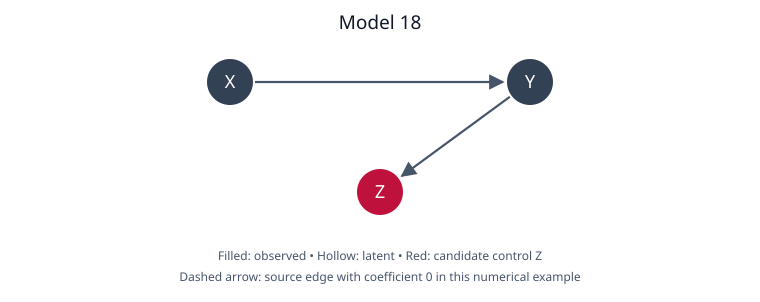

In [ ]:
draw_dag(
    title='Model 18',
    edges=[('x', 'y'), ('y', 'z')],
    positions={'x': (1, 2), 'z': (2, 1), 'y': (3, 2)},
)


### Numerical simulation

$$
\begin{aligned}
X &= \varepsilon_{X} \\
Y &= X + \varepsilon_{Y} \\
Z &= Y + \varepsilon_{Z}
\end{aligned}
$$

A unit increase in X increases Y directly by 1. Thus the total causal effect is 1.

Compare `Y ~ 1 + X` (population X slope 1) with `Y ~ 1 + X + Z` (0.5).


In [ ]:
def simulate_outcome_descendant(rng: np.random.Generator) -> Data:
    x = rng.standard_normal(N)
    y = x + rng.standard_normal(N)
    z = y + rng.standard_normal(N)
    return {"x": x, "y": y, "z": z}


data = simulate_outcome_descendant(stream("outcome_descendant:example"))
results["18"] = compare(data)


Y ~ 1 + X
  intercept=-0.015718   x= 1.029166
Y ~ 1 + X + Z
  intercept=-0.006978   x= 0.531624   z= 0.484497
Total causal effect from the structural equations: 1



## Compare all examples

The total effect is 1 throughout. Population slopes are the limits implied by these
particular structural equations, rather than causal conclusions drawn from a good fit.
“First” means unadjusted except in Model 15, where it conditions on W.
The final four rows summarize precision separately: a neutral control for bias can
still change how much estimates vary from dataset to dataset.


In [ ]:
lessons = {
    "1": "Removes bias", "2": "Removes bias", "3": "Removes bias",
    "4": "Removes bias", "5": "Removes bias", "6": "Removes bias",
    "7": "Introduces M-bias", "8": "Improves precision", "9": "Worsens precision",
    "10": "Amplifies bias", "11": "Blocks total effect", "12": "Overcontrol via proxy",
    "11v": "Misses total/direct effects", "13": "Improves precision",
    "14": "Worsens precision", "15": "Repairs W-induced bias",
    "16": "Collider bias", "17": "Collider bias", "18": "Case-control bias",
}
print(f"{'Model':<6} {'Controls':<13} {'ACE':>4} {'First X':>9} {'Adjusted X':>11}  Lesson")
for model, result in results.items():
    first, adjusted = result["first"]["x"], result["adjusted"]["x"]
    print(f"{model:<6} {result['controls']:<13} {1:4.1f} {first:9.5f} "
          f"{adjusted:11.5f}  {lessons[model]}")
print("\nPrecision experiments — adjusted/unadjusted sampling SD")
for model, result in precision_results.items():
    print(f"Model {model:>2}: {result['ratio']:.4f} "
          f"(asymptotic estimate from data {result['derived_ratio']:.4f})")


Model  Controls       ACE   First X  Adjusted X  Lesson
1      none -> Z      1.0   1.48848     1.00607  Removes bias
2      none -> Z      1.0   1.33127     0.98304  Removes bias
3      none -> Z      1.0   1.49934     1.00369  Removes bias
4      none -> Z      1.0   1.50142     1.01852  Removes bias
5      none -> Z      1.0   1.35743     1.01782  Removes bias
6      none -> Z      1.0   1.49013     0.99284  Removes bias
7      none -> Z      1.0   1.00755     1.83179  Introduces M-bias
8      none -> Z      1.0   1.02492     1.00573  Improves precision
9      none -> Z      1.0   0.99686     1.04132  Worsens precision
10     none -> Z      1.0   1.31929     1.98409  Amplifies bias
11     none -> Z      1.0   0.98594     0.02650  Blocks total effect
12     none -> Z      1.0   1.02566     0.51028  Overcontrol via proxy
11v    none -> Z      1.0   0.97375    -0.52451  Misses total/direct effects
13     none -> Z      1.0   1.09052     1.02664  Improves precision
14     none -> Z     